# Intelligent denoising based on autoencoders

### Motivation
Any photo can have noise, which can be low light, too high ISO etc. It is not only making images visually bad, but also can impact other phases in CV pipelines, like detection, classification etc.

Purpose of the project is to build intelectuall denoiser and compare it with Gaussian filtering

### Introduction
Existing methods:
- Gaussian blur, simple quick but blurs edges
- median filter, bilateral filter (keep edges).
- Non-Local Means, BM3D
- Neural net, e.g. denoising autoencoder DnCNN, UNet. Net trains on clear and noised images

Model based on the convolutional autoencoder from official Keras example ([Convolutional autoencoder for image denoising](https://keras.io/examples/vision/autoencoder), MNIST, Gaussian noise `0.4`). I  applied this approach to CIFAR10 color images, add salt n pepper noise and compare the results with classical filters in numbers.

In [1]:
import cv2
import numpy as np
import tensorflow as tf
from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

### Step 0: Dataset Inspection

For learning using CIFAR-10, whic is 60000 color images 32 by 32. Autoecnoder learns how to restore image, so it doesn't need classification

In [2]:
# loading dataset
(x_train, _), (x_test, _) = tf.keras.datasets.cifar10.load_data()

# normalization for memory saving
x_train = x_train.astype(np.float32)/255
x_test = x_test.astype(np.float32)/255

size = x_train.shape[1]

print('Train set:   ', len(x_train), 'samples')
print('Test set:    ', len(x_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


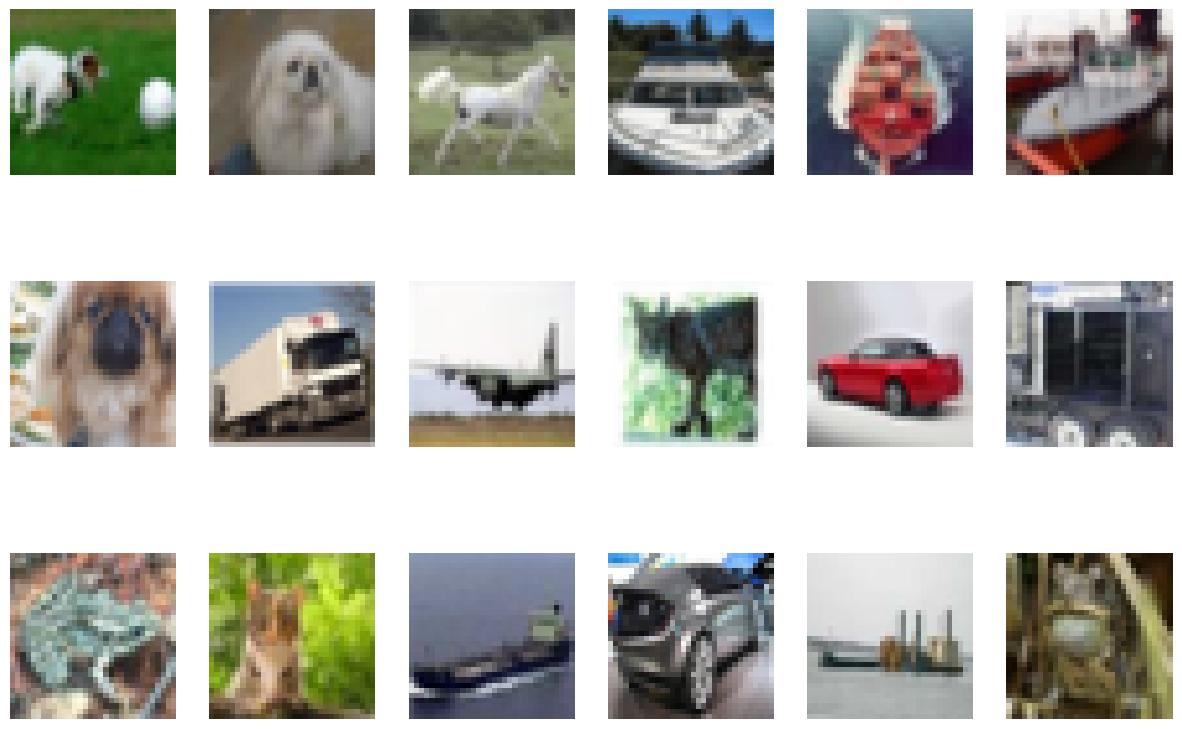

In [3]:
# dataset examples
for ii in range(18):
    idx = np.random.randint(len(x_train))
    plt.subplot(3,6,ii+1), plt.imshow(x_train[idx]), plt.axis('off')

### Step 1: Noise Models

Gonna use two types of noises salt&pepper and gausisan blur

In [4]:
sigma = 0.1          # gaus noise 
probability = 0.1    # %pixels for salt n pepper

def add_gaussian_noise(x, sigma=0.1):
    noisy = x + sigma*np.random.randn(*x.shape)
    return np.clip(noisy, 0, 1).astype(np.float32)

def add_salt_pepper(x, probability=0.1):
    noisy = x.copy()
    mask = np.random.rand(*x.shape[:-1]) < probability
    salt = np.random.rand(*x.shape[:-1]) < 0.5
    noisy[mask & salt] = 1
    noisy[mask & ~salt] = 0
    return noisy

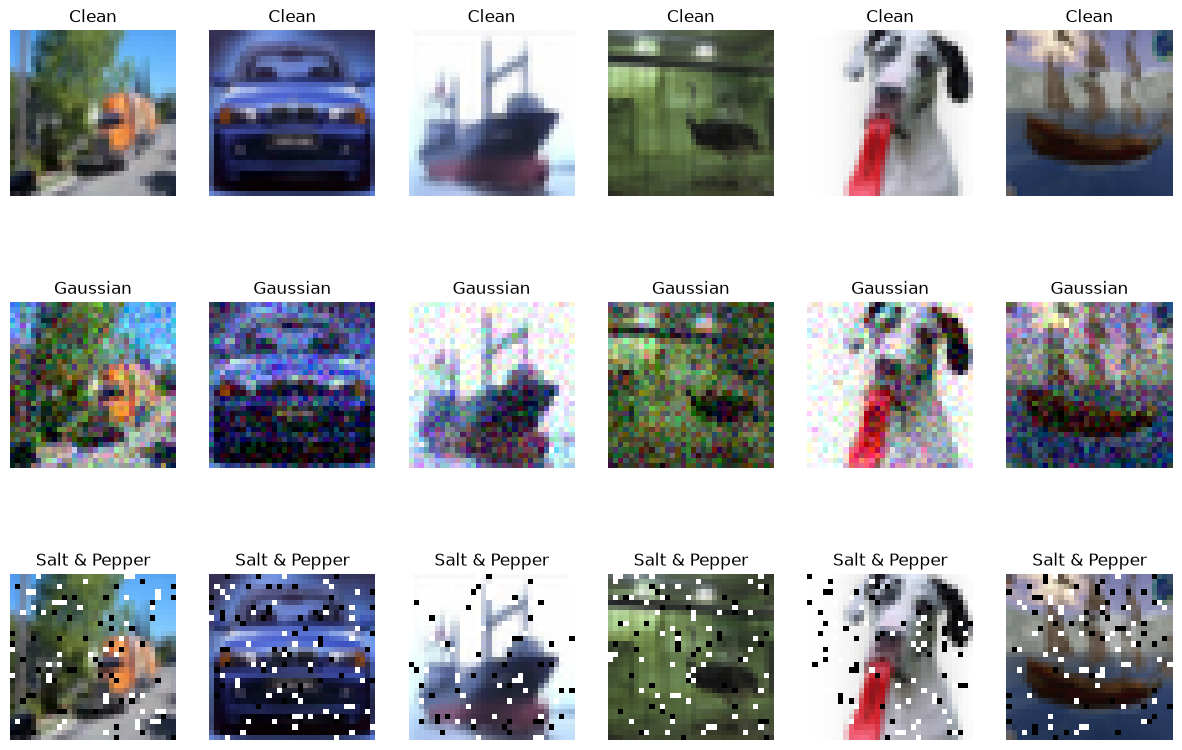

In [5]:
# noised selections compared no original images
x_test_gauss = add_gaussian_noise(x_test, sigma)
x_test_sp = add_salt_pepper(x_test, probability)

for ii in range(6):
    idx = np.random.randint(len(x_test))
    plt.subplot(3,6,ii+1), plt.imshow(x_test[idx]), plt.axis('off'), plt.title('Clean')
    plt.subplot(3,6,ii+7), plt.imshow(x_test_gauss[idx]), plt.axis('off'), plt.title('Gaussian')
    plt.subplot(3,6,ii+13), plt.imshow(x_test_sp[idx]), plt.axis('off'), plt.title('Salt & Pepper')

### Step 2: Classical Baselines

#### Metrics 
We will use 2 metrics for analyzing results

- PSNT (Peak Signal-to-Noise Ratio) More is better
- SSIM (Structural Similarity) measures how similar two images look by comparing their brightness, contrast, and details in small areas.

In [6]:
def psnr(clean, test):
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64))**2)
    return 10*np.log10(1.0/mse)

def evaluate(clean_set, test_set):
    p = tf.image.psnr(clean_set, test_set, max_val=1.0)
    s = tf.image.ssim(clean_set, test_set, max_val=1.0)
    return float(tf.reduce_mean(p)), float(tf.reduce_mean(s))

#### Filters

In [7]:
def to_uint8(x):
    return np.clip(255*x, 0, 255).round().astype(np.uint8)

def to_float(x):
    return x.astype(np.float32)/255

def gaussian_filter(images, ksize=5, sigma=5):
    return np.array([to_float(cv2.GaussianBlur(to_uint8(img), ksize=(ksize, ksize), sigmaX=sigma)) for img in images])

def median_filter(images, ksize=3):
    return np.array([to_float(cv2.medianBlur(to_uint8(img), ksize=ksize)) for img in images])

def bilateral_filter(images, d=5, sigma_color=75, sigma_space=75):
    return np.array([to_float(cv2.bilateralFilter(to_uint8(img), d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)) for img in images])

#### Parameters
To make a fair comparison with the autoencoder, we choose the best settings for each filter using PSNR on the validation set (the last 1000 training images), not the test set.

In [8]:
x_val = x_train[-1000:]
x_val_gauss = add_gaussian_noise(x_val, sigma)
x_val_sp = add_salt_pepper(x_val, probability)

# parameter grids
grids = {
    'gaussian':  [dict(ksize=k, sigma=s) for k in [3, 5, 7] for s in [0.5, 1, 2, 5]],
    'median':    [dict(ksize=k) for k in [3, 5]],
    'bilateral': [dict(d=d, sigma_color=c) for d in [3, 5, 7] for c in [50, 100, 150, 200]],
}
filters = {'gaussian': gaussian_filter, 'median': median_filter, 'bilateral': bilateral_filter}

best_params = {}
for noise_name, x_val_noisy in [('gaussian', x_val_gauss), ('salt_pepper', x_val_sp)]:
    for filter_name, grid in grids.items():
        scores = [evaluate(x_val, filters[filter_name](x_val_noisy, **params))[0] for params in grid]
        best = int(np.argmax(scores))
        best_params[(noise_name, filter_name)] = grid[best]
        print(f'{noise_name:12s} {filter_name:10s} best: {grid[best]}  PSNR = {scores[best]:.2f} dB')

gaussian     gaussian   best: {'ksize': 3, 'sigma': 1}  PSNR = 24.73 dB


gaussian     median     best: {'ksize': 3}  PSNR = 23.77 dB


gaussian     bilateral  best: {'d': 5, 'sigma_color': 100}  PSNR = 26.01 dB


salt_pepper  gaussian   best: {'ksize': 5, 'sigma': 1}  PSNR = 21.71 dB


salt_pepper  median     best: {'ksize': 3}  PSNR = 26.01 dB


salt_pepper  bilateral  best: {'d': 7, 'sigma_color': 200}  PSNR = 17.62 dB


#### Analyzing test set

* **Noisy** the image without processing (lower bound),
* **Gaussian / Median / Bilateral** - filters with the chosen parameters.

In [9]:
results = {}
test_sets = {'gaussian': x_test_gauss, 'salt_pepper': x_test_sp}

for noise_name, x_noisy in test_sets.items():
    results[(noise_name, 'Noisy')] = evaluate(x_test, x_noisy)
    for filter_name in filters:
        params = best_params[(noise_name, filter_name)]
        results[(noise_name, filter_name.capitalize())] = evaluate(x_test, filters[filter_name](x_noisy, **params))

def print_results(results):
    print(f'{"Noise":12s} {"Method":20s} {"PSNR, dB":>9s} {"SSIM":>7s}')
    for (noise_name, method), (p, s) in results.items():
        print(f'{noise_name:12s} {method:20s} {p:9.2f} {s:7.3f}')

print_results(results)

Noise        Method                PSNR, dB    SSIM
gaussian     Noisy                    20.33   0.654
gaussian     Gaussian                 24.71   0.812
gaussian     Median                   23.74   0.758
gaussian     Bilateral                26.00   0.848
salt_pepper  Noisy                    15.08   0.465
salt_pepper  Gaussian                 21.71   0.689
salt_pepper  Median                   25.98   0.865
salt_pepper  Bilateral                17.65   0.499


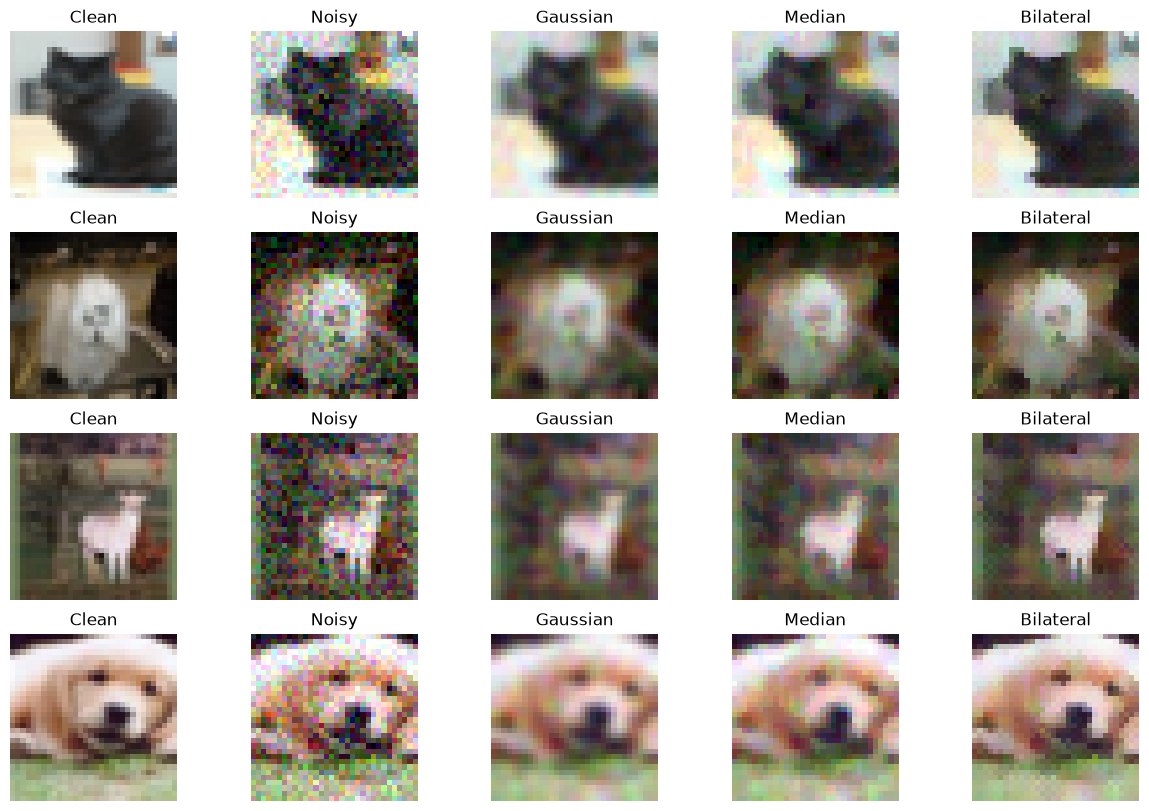

In [10]:
def show_baselines(x_noisy, noise_name, indices):
    methods = ['Clean', 'Noisy', 'Gaussian', 'Median', 'Bilateral']
    for row, idx in enumerate(indices):
        img = x_noisy[idx:idx+1]
        outs = [x_test[idx], x_noisy[idx]] + [filters[f](img, **best_params[(noise_name, f)])[0] for f in filters]
        for col, (title, out) in enumerate(zip(methods, outs)):
            plt.subplot(len(indices), len(methods), row*len(methods) + col + 1)
            plt.imshow(out), plt.axis('off'), plt.title(title)

indices = np.random.randint(len(x_test), size=4)
show_baselines(x_test_gauss, 'gaussian', indices)

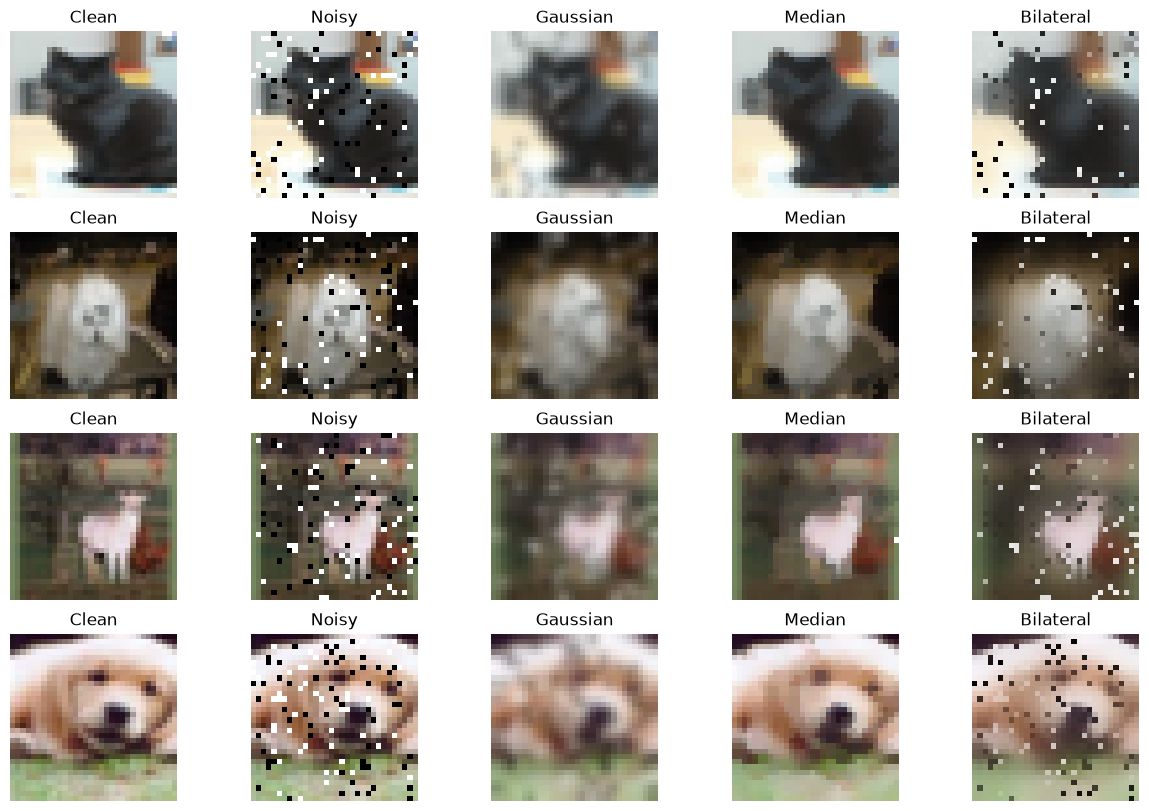

In [11]:
show_baselines(x_test_sp, 'salt_pepper', indices)

#### Conclusions for classical filters
* **Gaussian noise** the best classical method is bilateral filter. It smooths the noise and partially keeps the edges. Gaussian blur removes noise and details.
* **Salt n Pepper** median filter is the best. Gaussian and bilateral filters work badly with impulse noise: they spread the outliers to the neighbor pixels.

### Step 3: Building the Autoencoder

I took the architecture from the Keras example ([link](https://keras.io/examples/vision/autoencoder/)) and change it for color images
* **Encoder** two blocks `Conv2D(32) + MaxPooling2D`: 32×32 → 16×16 → 8×8. The network compresses the image and must keep only the important structure.
* **Decoder** two `Conv2DTranspose(strides=2)`: 8×8 → 16×16 → 32×32

The input shape is `(None, None, 3)`. So the same model works on images of any size.

Loss function in Keras example uses `binary_crossentropy`. I use `mse` PSNR is calculated directly from MSE, so minimizing MSE -> max PSNR.

In [12]:
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Input, MaxPooling2D, Concatenate
from tensorflow.keras import Model
from tensorflow.keras.callbacks import ModelCheckpoint

def psnr_metric(y_true, y_pred):
    return tf.image.psnr(y_true, y_pred, max_val=1.0)

def build_autoencoder():
    inputs = Input(shape=(None, None, 3))

    # Encoder
    net = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    net = MaxPooling2D((2, 2), padding='same')(net)
    net = Conv2D(32, (3, 3), activation='relu', padding='same')(net)
    net = MaxPooling2D((2, 2), padding='same')(net)

    # Decoder
    net = Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(net)
    net = Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(net)
    outputs = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(net)

    model = Model(inputs, outputs, name='autoencoder')
    model.compile(optimizer='adam', loss='mse', metrics=[psnr_metric])
    return model

model = build_autoencoder()
model.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, None, None, 32) │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, None, None, 32) │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, None, None, 32) │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, None, None, 3)  │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,507 (115.26 KB)

 Trainable params: 29,507 (115.26 KB)

 Non-trainable params: 0 (0.00 B)

### Step 4: Training

separate model for each noise type. generating the noisy training set once (as in the Keras example)

In [13]:
import os
os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

epochs = 20
batch_size = 128

x_train_gauss = add_gaussian_noise(x_train, sigma)
x_train_sp = add_salt_pepper(x_train, probability)

def train(model, x_noisy, name):
    weights_path = f'models/{name}.weights.h5'
    checkpoint = ModelCheckpoint(weights_path, monitor='val_loss', save_best_only=True, save_weights_only=True)
    start = time()
    history = model.fit(x_noisy, x_train, epochs=epochs, batch_size=batch_size, shuffle=True,
                        validation_split=0.1, callbacks=[checkpoint], verbose=2)
    print(f'Training time: {time() - start:.0f} s')
    model.load_weights(weights_path)
    return history

def plot_history(history):
    h = history.history
    epochs_range = range(len(h['loss']))

    plt.subplot(121), plt.plot(epochs_range, h['loss'], '.-', epochs_range, h['val_loss'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss (MSE)')
    plt.legend(['Train', 'Validation'])
    plt.subplot(122), plt.plot(epochs_range, h['psnr_metric'], '.-', epochs_range, h['val_psnr_metric'], '.-')
    plt.grid(True), plt.xlabel('epochs'), plt.ylabel('PSNR, dB')
    plt.legend(['Train', 'Validation'])

    print('Train PSNR     ', h['psnr_metric'][-1])
    print('Validation PSNR', h['val_psnr_metric'][-1])

In [14]:
# Model for Gaussian noise
ae_gauss = build_autoencoder()
history_gauss = train(ae_gauss, x_train_gauss, 'ae_gaussian')

Epoch 1/20


352/352 - 22s - 62ms/step - loss: 0.0152 - psnr_metric: 19.6229 - val_loss: 0.0074 - val_psnr_metric: 21.7703


Epoch 2/20


352/352 - 20s - 58ms/step - loss: 0.0069 - psnr_metric: 22.0753 - val_loss: 0.0063 - val_psnr_metric: 22.4797


Epoch 3/20


352/352 - 24s - 68ms/step - loss: 0.0061 - psnr_metric: 22.6105 - val_loss: 0.0056 - val_psnr_metric: 22.9854


... (31 outputs left out)

352/352 - 18s - 51ms/step - loss: 0.0036 - psnr_metric: 24.7892 - val_loss: 0.0036 - val_psnr_metric: 24.7934


Epoch 20/20


352/352 - 18s - 51ms/step - loss: 0.0036 - psnr_metric: 24.8322 - val_loss: 0.0036 - val_psnr_metric: 24.8578


Training time: 402 s


Train PSNR      24.832197189331055
Validation PSNR 24.85784912109375


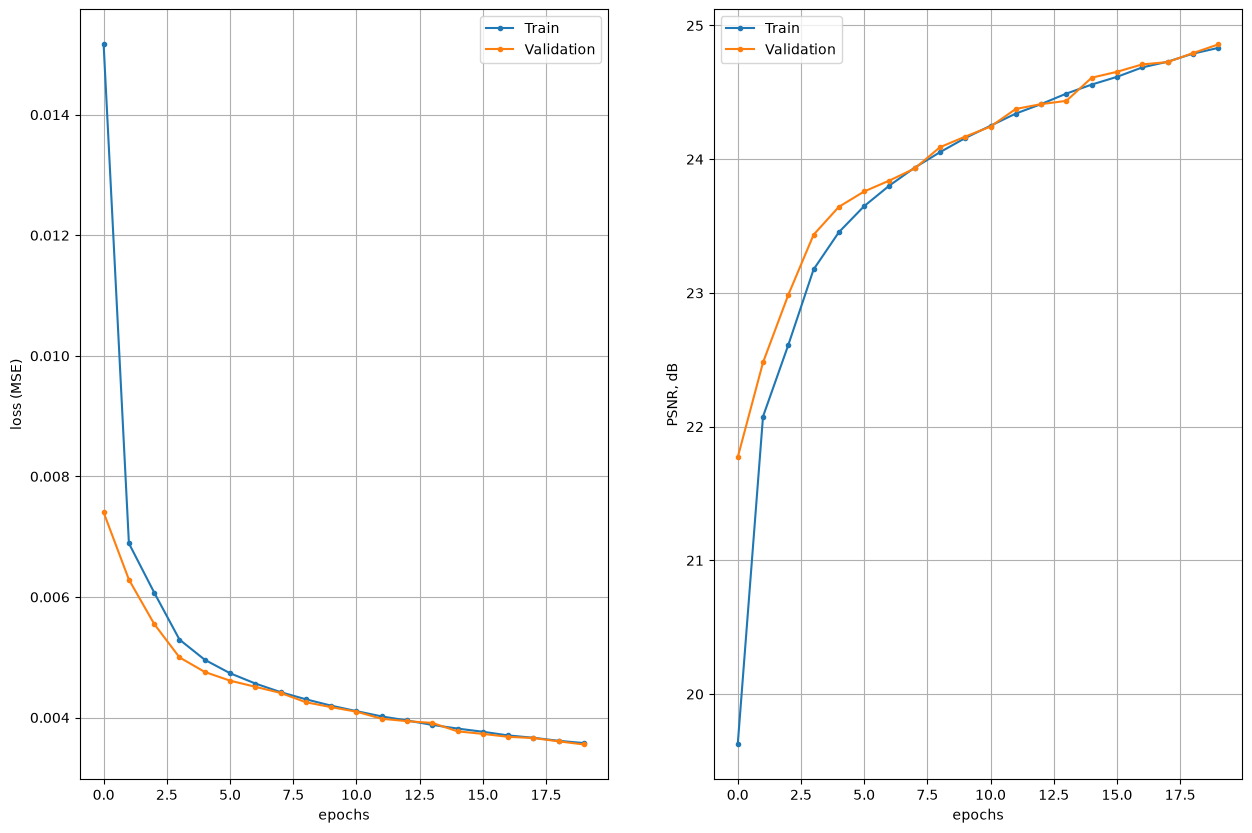

In [15]:
plot_history(history_gauss)

In [16]:
# Model for salt & pepper noise
ae_sp = build_autoencoder()
history_sp = train(ae_sp, x_train_sp, 'ae_salt_pepper')

Epoch 1/20


352/352 - 22s - 63ms/step - loss: 0.0166 - psnr_metric: 18.9534 - val_loss: 0.0088 - val_psnr_metric: 20.9167


Epoch 2/20


352/352 - 22s - 62ms/step - loss: 0.0082 - psnr_metric: 21.2629 - val_loss: 0.0075 - val_psnr_metric: 21.6651


Epoch 3/20


352/352 - 20s - 58ms/step - loss: 0.0071 - psnr_metric: 21.8657 - val_loss: 0.0065 - val_psnr_metric: 22.2686


... (31 outputs left out)

352/352 - 19s - 55ms/step - loss: 0.0042 - psnr_metric: 24.1868 - val_loss: 0.0045 - val_psnr_metric: 23.8230


Epoch 20/20


352/352 - 21s - 60ms/step - loss: 0.0042 - psnr_metric: 24.2425 - val_loss: 0.0045 - val_psnr_metric: 23.8523


Training time: 410 s


Train PSNR      24.24248695373535
Validation PSNR 23.85228729248047


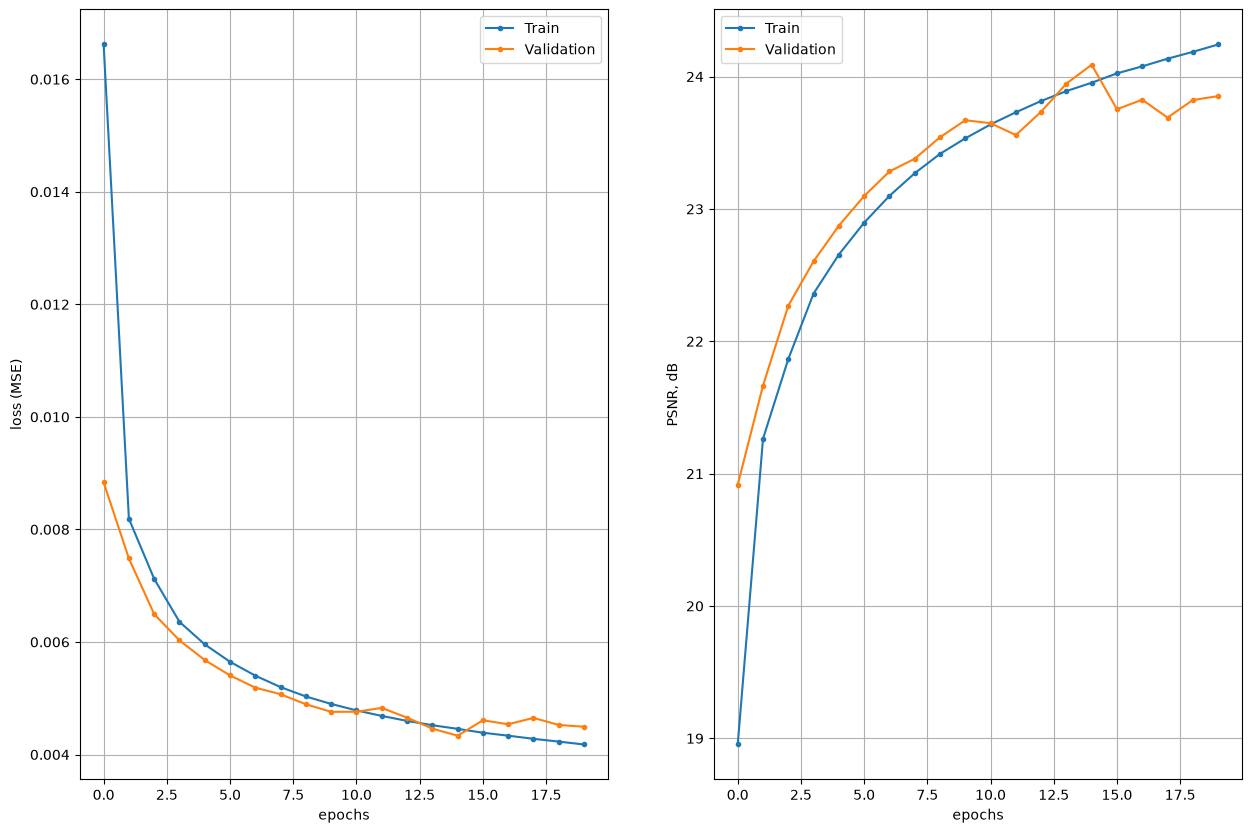

In [17]:
plot_history(history_sp)

### Step 5: Compare

compare the autoencoder with the classical filters on the same 10000 test images as in Step 2.

In [18]:
models = {'gaussian': ae_gauss, 'salt_pepper': ae_sp}
denoised = {}

for noise_name, x_noisy in test_sets.items():
    denoised[noise_name] = models[noise_name].predict(x_noisy, batch_size=256, verbose=0)
    results[(noise_name, 'Autoencoder')] = evaluate(x_test, denoised[noise_name])

print_results(results)

Noise        Method                PSNR, dB    SSIM
gaussian     Noisy                    20.33   0.654
gaussian     Gaussian                 24.71   0.812
gaussian     Median                   23.74   0.758
gaussian     Bilateral                26.00   0.848
salt_pepper  Noisy                    15.08   0.465
salt_pepper  Gaussian                 21.71   0.689
salt_pepper  Median                   25.98   0.865
salt_pepper  Bilateral                17.65   0.499
gaussian     Autoencoder              24.84   0.810
salt_pepper  Autoencoder              24.05   0.777


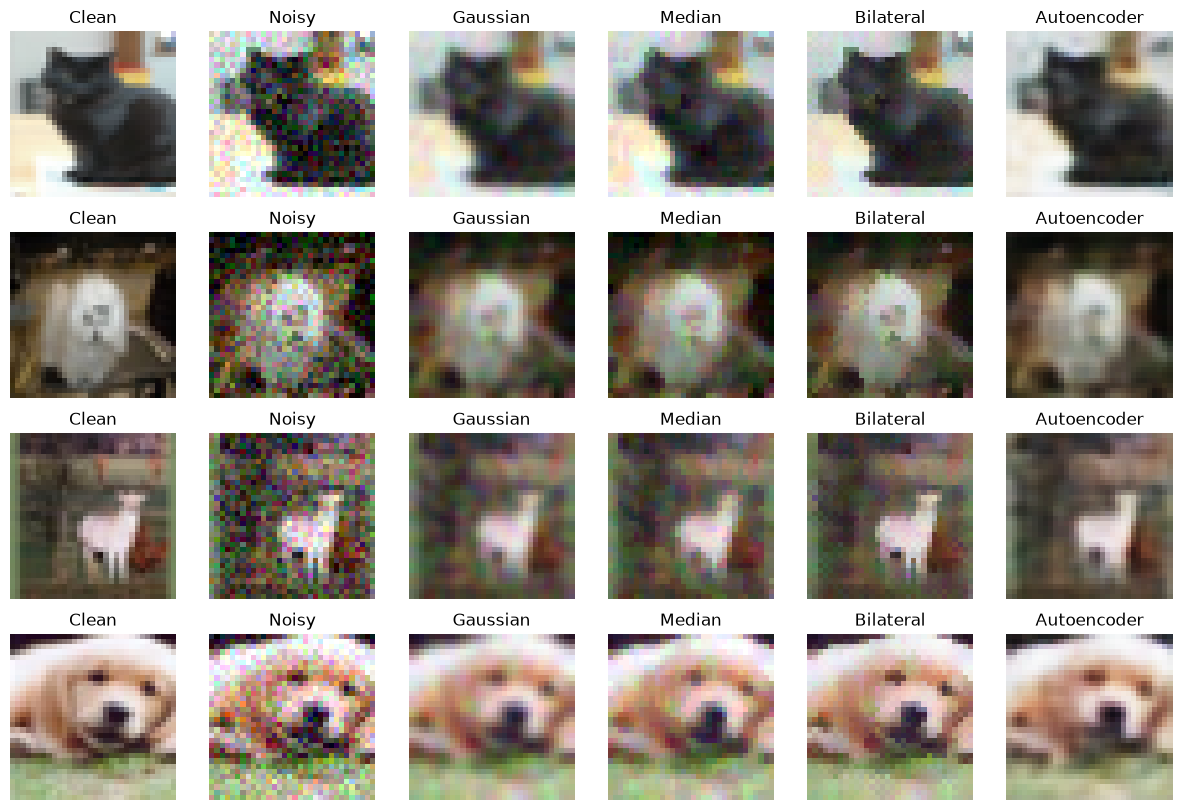

In [19]:
def show_comparison(noise_name, path):
    x_noisy = test_sets[noise_name]
    titles = ['Clean', 'Noisy', 'Gaussian', 'Median', 'Bilateral', 'Autoencoder']
    for row, idx in enumerate(indices):
        img = x_noisy[idx:idx+1]
        outs = [x_test[idx], x_noisy[idx]] + [filters[f](img, **best_params[(noise_name, f)])[0] for f in filters] + [denoised[noise_name][idx]]
        for col in range(len(titles)):
            plt.subplot(len(indices), len(titles), row*len(titles) + col + 1)
            plt.imshow(outs[col]), plt.axis('off'), plt.title(titles[col])
    plt.savefig(path, bbox_inches='tight')

show_comparison('gaussian', 'results/cifar_gaussian.png')

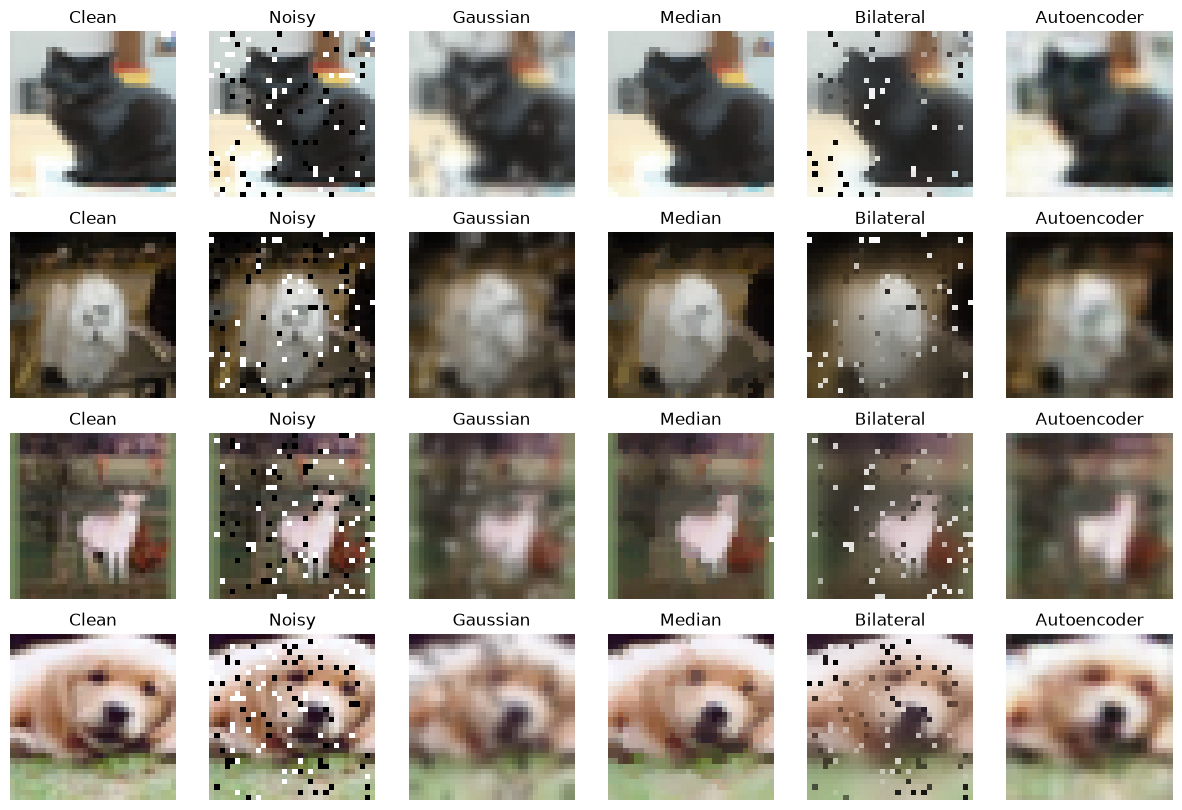

In [20]:
show_comparison('salt_pepper', 'results/cifar_salt_pepper.png')

#### Speed
Time to process one 32×32 image (mean over 10000 test images, CPU).

In [21]:
start = time()
bilateral_filter(x_test_gauss, **best_params[('gaussian', 'bilateral')])
print(f'Bilateral:   {(time() - start)/len(x_test)*1000:.3f} ms / image')

start = time()
ae_gauss.predict(x_test_gauss, batch_size=256, verbose=0)
print(f'Autoencoder: {(time() - start)/len(x_test)*1000:.3f} ms / image')

Bilateral:   0.032 ms / image


Autoencoder: 0.106 ms / image


bilateral filter process one 32×32 image in ~0.03 ms, autoencoder in ~0.11 ms.network is ~3.5 times slower, but on CPU it still processes ~9000 images per second.

#### Robustness to the noise level

model is trained on `sigma = 0.1`. testing with different noise level

Noisy         26.18  20.32  14.80  11.94  10.22
Gaussian      26.43  24.71  21.36  18.88  17.11
Bilateral     29.01  26.00  18.91  14.30  11.75
Autoencoder   25.38  24.84  22.51  20.24  18.48


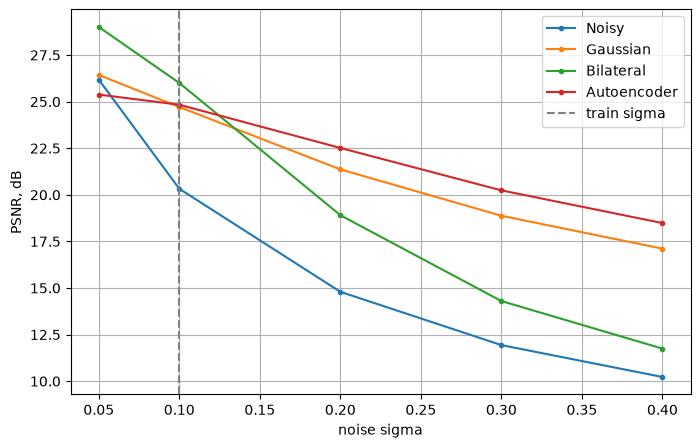

In [22]:
sigmas = [0.05, 0.1, 0.2, 0.3, 0.4]
sweep = {'Noisy': [], 'Gaussian': [], 'Bilateral': [], 'Autoencoder': []}

for s in sigmas:
    x_noisy = add_gaussian_noise(x_test, s)
    sweep['Noisy'].append(evaluate(x_test, x_noisy)[0])
    sweep['Gaussian'].append(evaluate(x_test, gaussian_filter(x_noisy, **best_params[('gaussian', 'gaussian')]))[0])
    sweep['Bilateral'].append(evaluate(x_test, bilateral_filter(x_noisy, **best_params[('gaussian', 'bilateral')]))[0])
    sweep['Autoencoder'].append(evaluate(x_test, ae_gauss.predict(x_noisy, batch_size=256, verbose=0))[0])

plt.figure(figsize=(8, 5))
for name, values in sweep.items():
    plt.plot(sigmas, values, '.-', label=name)
plt.axvline(sigma, color='gray', linestyle='--', label='train sigma')
plt.grid(True), plt.xlabel('noise sigma'), plt.ylabel('PSNR, dB'), plt.legend()
plt.savefig('results/noise_sweep.png', bbox_inches='tight')

for name, values in sweep.items():
    print(f'{name:12s}', ' '.join(f'{v:6.2f}' for v in values))

#### Conclusions for the base autoencoder
* **Quality.** On Gaussian noise the base model from the Keras example gives 24.84 dB slight better results against Gaussian filter 24.71 dB, but worse than bilateral 26.00 dB. On salt & pepper it gives 24.05 dB against 25.98 dB for median.
* **Reason** — 8×8×32 bottleneck. network loses small details, and the result is blurred (see the images above). This is enough for MNIST (the Keras example), but not for color photos.

with weak noise (`sigma=0.05`) the autoencoder even makes the image worse (25.38dB against 26.18dB) the model is trained on stronger noise and smooths too much

### Step 6: Improvement — Skip Connections

In autoencoder all image details should ne passed through the 8 by 8 bottleneck.  network loses small details, and the result is a bit blurred.


The solution is skip connections as in UNet, output of each encoder block goes directly to the matching decoder block (`Concatenate`). Then  decoder gets both the compressed "clean" information and the details at the original resolution.

In [23]:
def build_skip_autoencoder():
    inputs = Input(shape=(None, None, 3))

    # Encoder
    c1 = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)       # 32x32
    p1 = MaxPooling2D((2, 2), padding='same')(c1)
    c2 = Conv2D(64, (3, 3), activation='relu', padding='same')(p1)           # 16x16
    p2 = MaxPooling2D((2, 2), padding='same')(c2)

    # Bottleneck
    b = Conv2D(64, (3, 3), activation='relu', padding='same')(p2)            # 8x8

    # Decoder + skip connections
    u2 = Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same')(b)
    u2 = Concatenate()([u2, c2])
    u2 = Conv2D(64, (3, 3), activation='relu', padding='same')(u2)           # 16x16
    u1 = Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same')(u2)
    u1 = Concatenate()([u1, c1])
    u1 = Conv2D(32, (3, 3), activation='relu', padding='same')(u1)           # 32x32
    outputs = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(u1)

    model = Model(inputs, outputs, name='skip_autoencoder')
    model.compile(optimizer='adam', loss='mse', metrics=[psnr_metric])
    return model

build_skip_autoencoder().summary()

Model: "skip_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, None,      │        896 │ input_layer_3[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, None,      │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, None,      │     18,496 │ max_pooling2d_6[… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, None,      │          0 │ conv2d_10[0][0]   │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, None,      │     36,928 │ max_pooling2d_7[… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, None,      │     36,928 │ conv2d_11[0][0]   │
│ (Conv2DTranspose)   │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None,      │          0 │ conv2d_transpose… │
│ (Concatenate)       │ None, 128)        │            │ conv2d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, None,      │     73,792 │ concatenate[0][0] │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_7  │ (None, None,      │     18,464 │ conv2d_12[0][0]   │
│ (Conv2DTranspose)   │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, None,      │          0 │ conv2d_transpose… │
│ (Concatenate)       │ None, 64)         │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, None,      │     18,464 │ concatenate_1[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, None,      │        867 │ conv2d_13[0][0]   │
│                     │ None, 3)          │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 204,835 (800.14 KB)

 Trainable params: 204,835 (800.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


352/352 - 71s - 202ms/step - loss: 0.0067 - psnr_metric: 23.9618 - val_loss: 0.0024 - val_psnr_metric: 26.3451


Epoch 2/20


352/352 - 72s - 204ms/step - loss: 0.0023 - psnr_metric: 26.4952 - val_loss: 0.0022 - val_psnr_metric: 26.8036


Epoch 3/20


352/352 - 72s - 204ms/step - loss: 0.0022 - psnr_metric: 26.8093 - val_loss: 0.0021 - val_psnr_metric: 26.9555


... (31 outputs left out)

352/352 - 73s - 207ms/step - loss: 0.0016 - psnr_metric: 28.0140 - val_loss: 0.0016 - val_psnr_metric: 28.0229


Epoch 20/20


352/352 - 67s - 190ms/step - loss: 0.0016 - psnr_metric: 28.0584 - val_loss: 0.0016 - val_psnr_metric: 28.0837


Training time: 1414 s
Train PSNR      28.058353424072266
Validation PSNR 28.083675384521484


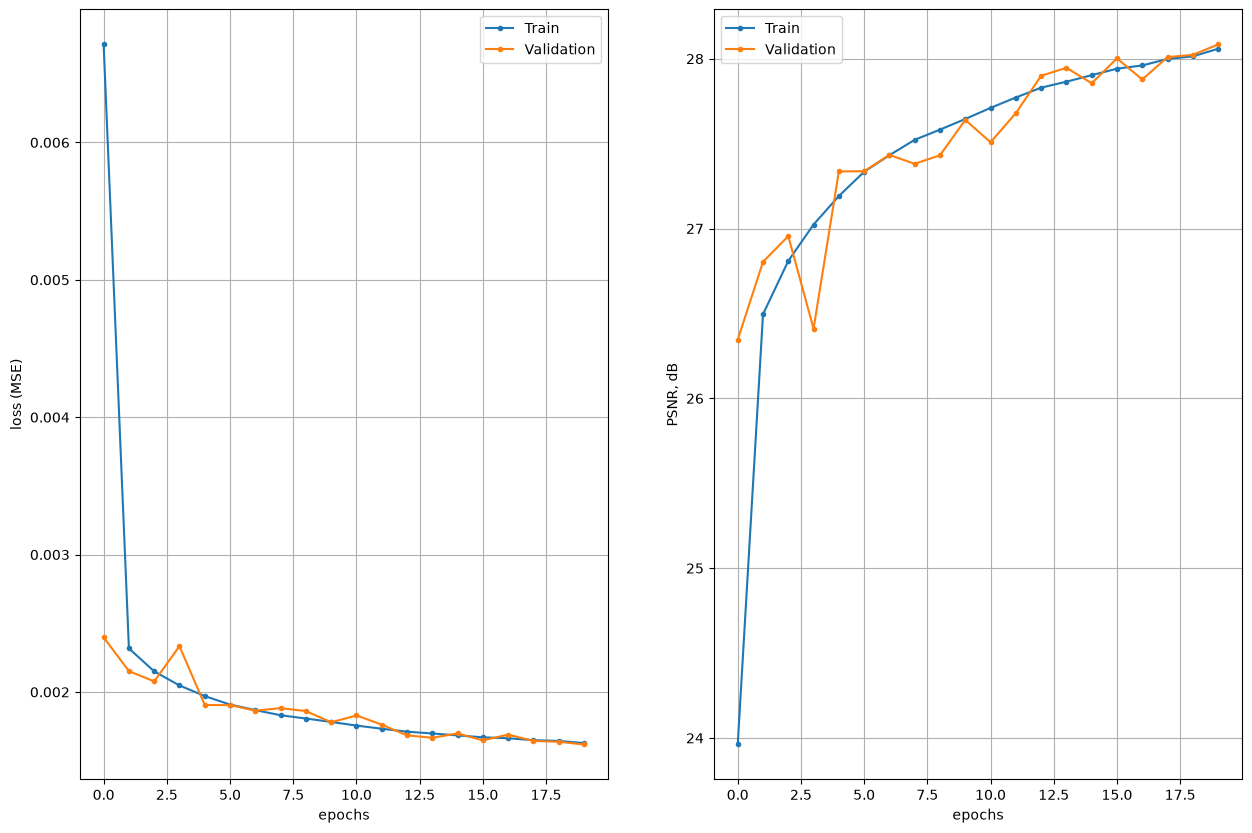

In [24]:
skip_gauss = build_skip_autoencoder()
history_skip_gauss = train(skip_gauss, x_train_gauss, 'skip_gaussian')
plot_history(history_skip_gauss)

Epoch 1/20


352/352 - 68s - 193ms/step - loss: 0.0088 - psnr_metric: 21.8674 - val_loss: 0.0037 - val_psnr_metric: 24.6066


Epoch 2/20


352/352 - 66s - 186ms/step - loss: 0.0028 - psnr_metric: 26.0314 - val_loss: 0.0020 - val_psnr_metric: 27.5134


Epoch 3/20


352/352 - 65s - 186ms/step - loss: 0.0017 - psnr_metric: 28.0413 - val_loss: 0.0015 - val_psnr_metric: 28.7171


... (31 outputs left out)

352/352 - 77s - 218ms/step - loss: 4.5382e-04 - psnr_metric: 33.9872 - val_loss: 4.2336e-04 - val_psnr_metric: 34.3050


Epoch 20/20


352/352 - 76s - 217ms/step - loss: 4.3951e-04 - psnr_metric: 34.1154 - val_loss: 4.2739e-04 - val_psnr_metric: 34.2133


Training time: 1363 s
Train PSNR      34.11540603637695
Validation PSNR 34.21331787109375


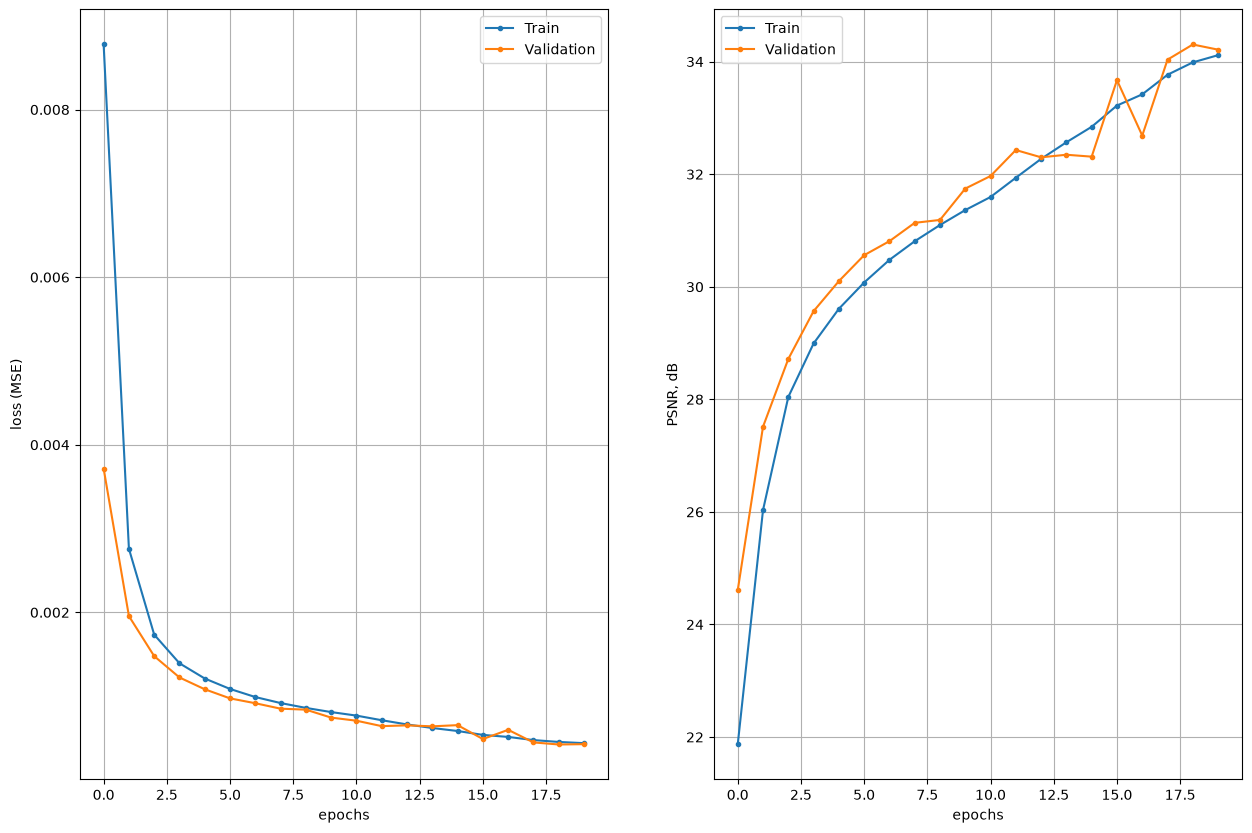

In [25]:
skip_sp = build_skip_autoencoder()
history_skip_sp = train(skip_sp, x_train_sp, 'skip_salt_pepper')
plot_history(history_skip_sp)

In [26]:
skip_models = {'gaussian': skip_gauss, 'salt_pepper': skip_sp}
denoised_skip = {}

for noise_name, x_noisy in test_sets.items():
    denoised_skip[noise_name] = skip_models[noise_name].predict(x_noisy, batch_size=256, verbose=0)
    results[(noise_name, 'Skip Autoencoder')] = evaluate(x_test, denoised_skip[noise_name])

print_results(results)

Noise        Method                PSNR, dB    SSIM
gaussian     Noisy                    20.33   0.654
gaussian     Gaussian                 24.71   0.812
gaussian     Median                   23.74   0.758
gaussian     Bilateral                26.00   0.848
salt_pepper  Noisy                    15.08   0.465
salt_pepper  Gaussian                 21.71   0.689
salt_pepper  Median                   25.98   0.865
salt_pepper  Bilateral                17.65   0.499
gaussian     Autoencoder              24.84   0.810
salt_pepper  Autoencoder              24.05   0.777
gaussian     Skip Autoencoder         28.07   0.906
salt_pepper  Skip Autoencoder         34.25   0.980


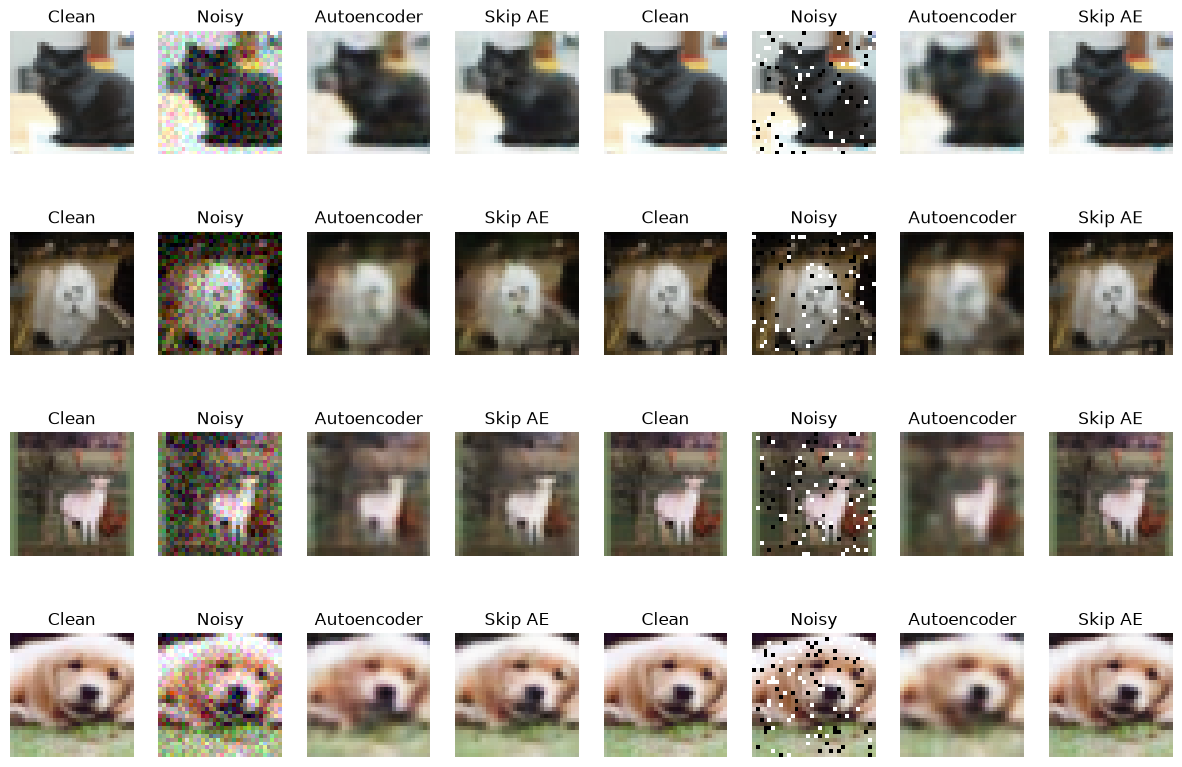

In [27]:
# vase autoencoder vs skip connections
for row, idx in enumerate(indices):
    for col, noise_name in enumerate(['gaussian', 'salt_pepper']):
        outs = [x_test[idx], test_sets[noise_name][idx], denoised[noise_name][idx], denoised_skip[noise_name][idx]]
        titles = ['Clean', 'Noisy', 'Autoencoder', 'Skip AE']
        for k, (title, out) in enumerate(zip(titles, outs)):
            plt.subplot(len(indices), 8, row*8 + col*4 + k + 1)
            plt.imshow(out), plt.axis('off'), plt.title(title)
plt.savefig('results/cifar_skip.png', bbox_inches='tight')

#### results summ
* gaussian noise is 2.1 dB better than bilateral and 3.2 dB better than base autoencoder.
* Salt & pepper 8.3 dB better than the median filter.
* The train and validation curves are almost the same, so there is no overfitting.

### Step 7: Demo

models were trained only on 32 by 32 images. now lets check 768×512 kodak photos from  `data/` folder. network is fully convolutional, so we can apply it to an image of any size without changes.

In [28]:
import glob

kodak = [cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB).astype(np.float32)/255
         for path in sorted(glob.glob('data/kodim*.png'))]
kodak = np.array([img if img.shape[0] < img.shape[1] else np.rot90(img) for img in kodak])
print('Kodak:', kodak.shape)

kodak_noisy = {'gaussian': add_gaussian_noise(kodak, sigma), 'salt_pepper': add_salt_pepper(kodak, probability)}

Kodak: (8, 512, 768, 3)


In [29]:
kodak_results = {}
kodak_out = {}

for noise_name, x_noisy in kodak_noisy.items():
    outs = {'Noisy': x_noisy}
    for f in filters:
        outs[f.capitalize()] = filters[f](x_noisy, **best_params[(noise_name, f)])
    outs['Autoencoder'] = models[noise_name].predict(x_noisy, batch_size=1, verbose=0)
    outs['Skip Autoencoder'] = skip_models[noise_name].predict(x_noisy, batch_size=1, verbose=0)
    kodak_out[noise_name] = outs
    for method, out in outs.items():
        kodak_results[(noise_name, method)] = evaluate(kodak, out)

print_results(kodak_results)

Noise        Method                PSNR, dB    SSIM
gaussian     Noisy                    20.41   0.319
gaussian     Gaussian                 26.48   0.640
gaussian     Median                   25.71   0.561
gaussian     Bilateral                27.80   0.680
gaussian     Autoencoder              27.04   0.740
gaussian     Skip Autoencoder         30.21   0.822
salt_pepper  Noisy                    14.95   0.205
salt_pepper  Gaussian                 23.18   0.491
salt_pepper  Median                   29.92   0.875
salt_pepper  Bilateral                17.69   0.269
salt_pepper  Autoencoder              26.68   0.723
salt_pepper  Skip Autoencoder         34.82   0.946


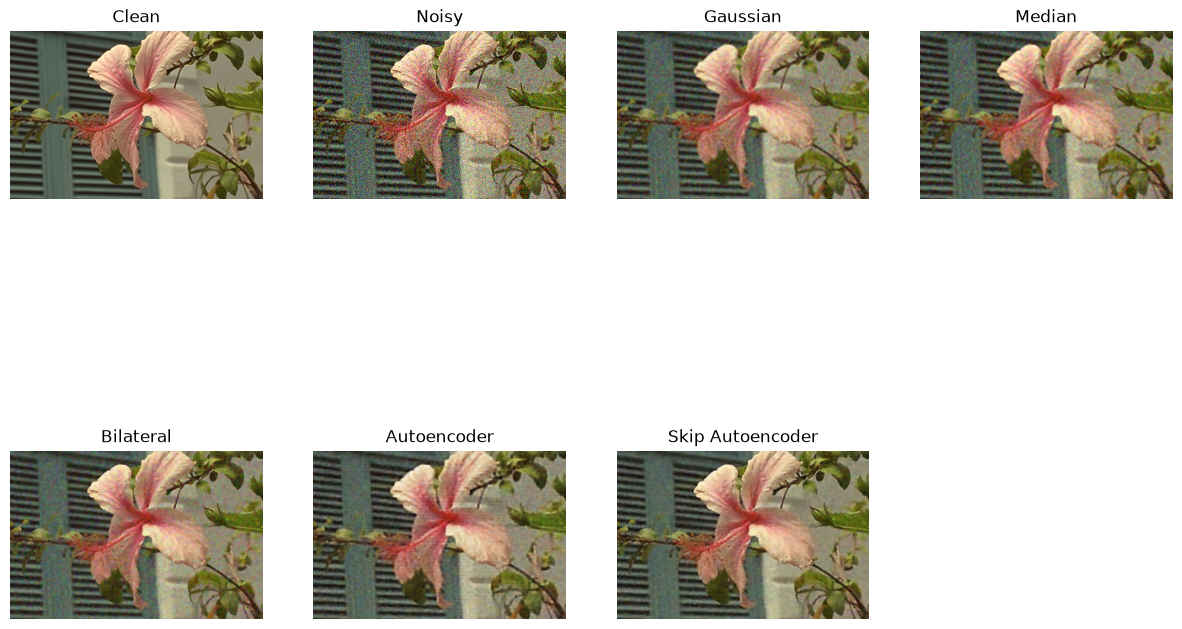

In [30]:
def show_kodak(noise_name, idx, crop=(slice(150, 350), slice(250, 550)), path=None):
    outs = kodak_out[noise_name]
    titles = ['Clean'] + list(outs.keys())
    images = [kodak[idx]] + [out[idx] for out in outs.values()]
    for k, (title, img) in enumerate(zip(titles, images)):
        plt.subplot(2, 4, k + 1), plt.imshow(img[crop]), plt.axis('off'), plt.title(title)
    if path:
        plt.savefig(path, bbox_inches='tight')

show_kodak('gaussian', 3, path='results/kodak_gaussian.png')

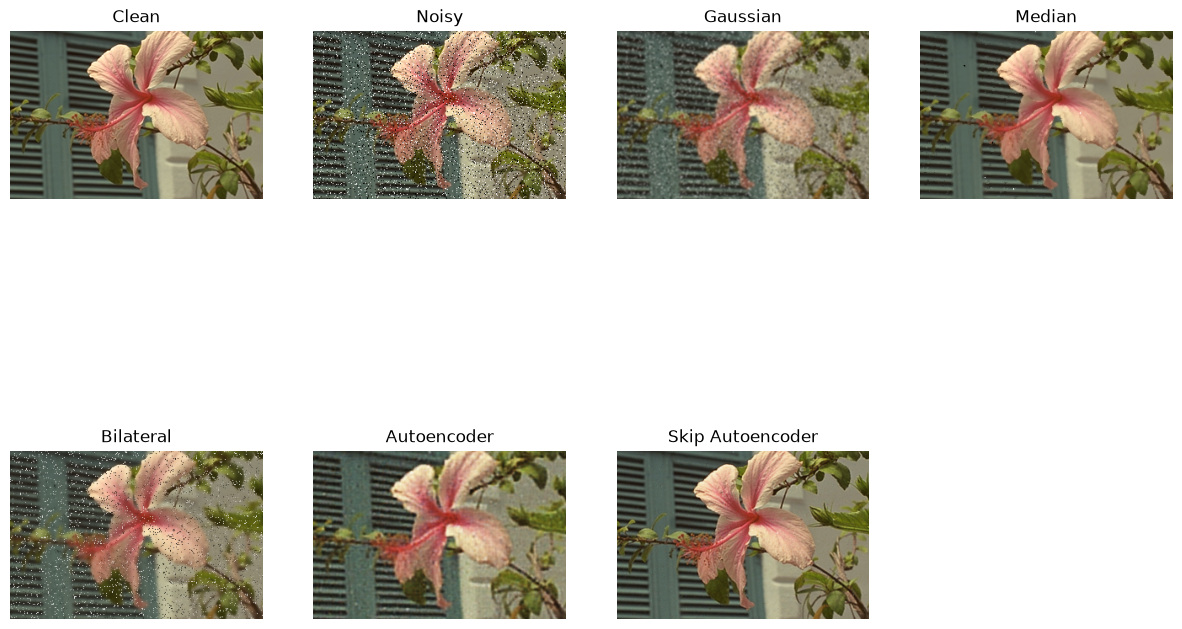

In [31]:
show_kodak('salt_pepper', 3, path='results/kodak_salt_pepper.png')

## Results & Conclusions

### Summary table
| Method | Gaussian| Salt & Pepper |
|--------|------------------------|--------------------------|
| Noisy | 20.33 / 0.654 | 15.08 / 0.465 |
| Gaussian | 24.71 / 0.812 | 21.71 / 0.689 |
| Median | 23.74 / 0.758 | 25.98 / 0.865 |
| Bilateral | 26.00 / 0.848 | 17.65 / 0.499 |
| Autoencoder (Keras example) | 24.84 / 0.810 | 24.05 / 0.777 |
| **Autoencoder with skip connections** | **28.07 / 0.906** | **34.25 / 0.980** |

### Strengths

autoencoder with skip connections is the best, and the same architecture works for both Gaussian and impulse noise. Filters need a different method for each noise type.

### Weaknesses
separate model for each noise type; the quality drops if the test noise level is different from the training noise level.

### Future work
New noise at each epoch (augmentation) instead of one fixed noisy training set.
Train one model on a range of noise levels (for example, `sigma` from 0.05 to 0.3), so that it also works when the noise level changes.